# PlantSeg Stage 4 — XAI Faithfulness Analysis (all 6 architectures)

**No training in this notebook.** All 6 models are loaded directly from `.pt` checkpoints.
Run `PlantSeg_Stage4_Trainer.ipynb` first to get the two missing `.pt` files, then attach
all 6 as a single Kaggle dataset before running this.

### Cross-architecture explanation strategy
| Architecture type | Method | Rationale |
|---|---|---|
| CNN encoder-decoder (`UNet`, `UNet++`, `DeepLabV3+` ×2, `FPN`) | **Grad-CAM** | Hooks last decoder feature map; standard and faithful for conv nets |
| Transformer encoder (`SegFormer-B2`) | **Attention-rollout** | Grad-CAM is not faithful for self-attention; rollout accumulates attention through transformer depth |

### Faithfulness metrics
1. **CAM–GT mask overlap** — IoU + pointing-game hit rate (CAM binarized at the true lesion area-fraction, no arbitrary threshold)
2. **Deletion AUC** — progressively grey out the top-CAM pixels; faithful explanations cause a fast confidence drop (low AUC = more faithful)

### Required Kaggle inputs
- PlantSeg dataset
- All 6 `.pt` checkpoints in one dataset (auto-detected by `CKPT_ROOT`)

### Expected runtime
~20–30 minutes (pure inference + XAI over 300-image stratified subset, no training).


**Setup:**

In [1]:
!pip install -q segmentation-models-pytorch albumentations
import os, json, glob, warnings, time
from pathlib import Path
from collections import defaultdict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.cm as mpl_cm, seaborn as sns
from PIL import Image, ImageDraw
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
from transformers import SegformerForSemanticSegmentation
from scipy import stats
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid", context="talk")
SEED=42; torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| smp", smp.__version__)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 4.0 MB/s eta 0:00:00
Device: cuda | smp 0.5.0


**Config — set `CKPT_ROOT` to the dataset containing all 6 `.pt` files:**

In [2]:
DATA_ROOT = Path("/kaggle/input/datasets/marufbangabashi/plantseg/plantseg")
if not (DATA_ROOT/"Metadata.csv").exists():
    for c in [Path("/kaggle/input/plantseg"), Path("plantseg"), Path(".")]:
        if (c/"Metadata.csv").exists(): DATA_ROOT = c; break
    else:
        cand = glob.glob("/kaggle/input/**/Metadata.csv", recursive=True)
        if cand: DATA_ROOT = Path(cand[0]).parent
assert (DATA_ROOT/"Metadata.csv").exists(), "Metadata.csv not found."

_required = {"UNetPP_resnet50.pt","DeepLabV3Plus_resnet50.pt","FPN_resnet50.pt",
             "SegFormer_b2.pt","DeepLabV3Plus_efficientnet-b3.pt","UNet_resnet34.pt"}
CKPT_ROOT = None
for _d in glob.glob("/kaggle/input/*"):
    if all((Path(_d)/f).exists() for f in _required): CKPT_ROOT=Path(_d); break
if CKPT_ROOT is None:
    _cand = glob.glob("/kaggle/input/**/UNetPP_resnet50.pt", recursive=True)
    if _cand: CKPT_ROOT = Path(_cand[0]).parent
assert CKPT_ROOT, "Could not find all 6 .pt files — check that the checkpoint dataset is attached."

CHECKPOINTS = {
    "DeepLabV3Plus_efficientnet-b3": CKPT_ROOT/"DeepLabV3Plus_efficientnet-b3.pt",
    "UNet_resnet34":                  CKPT_ROOT/"UNet_resnet34.pt",
    "UNetPP_resnet50":                CKPT_ROOT/"UNetPP_resnet50.pt",
    "FPN_resnet50":                   CKPT_ROOT/"FPN_resnet50.pt",
    "DeepLabV3Plus_resnet50":         CKPT_ROOT/"DeepLabV3Plus_resnet50.pt",
    "SegFormer_b2":                   CKPT_ROOT/"SegFormer_b2.pt",
}
OUTDIR = Path("/kaggle/working/s4_results"); FIG = OUTDIR/"figures"
OUTDIR.mkdir(parents=True, exist_ok=True); FIG.mkdir(exist_ok=True)
IMG_SIZE=512; N_XAI=300; DEL_STEPS=10
TRANSFORMER_MODELS = {"SegFormer_b2"}

# Load Stage 3 cross-link table — REQUIRED (no fallback, no hardcoded values).
# Attach severity_vs_segmentation_quality.csv from your Stage 3 output as a Kaggle dataset.
_s3_csv = glob.glob("/kaggle/input/**/severity_vs_segmentation_quality.csv", recursive=True)
assert _s3_csv, (
    "severity_vs_segmentation_quality.csv not found under /kaggle/input.\n"
    "Attach the Stage 3 output dataset before running Stage 4.")
S3_CSV_PATH = _s3_csv[0]
stage3_ref = (pd.read_csv(S3_CSV_PATH, index_col=0)[["fg_IoU","ccc"]]
              .rename(columns={"fg_IoU":"fg_iou","ccc":"severity_ccc"}))
stage3_ref.index.name = "model"
print(f"Loaded Stage 3 reference from: {S3_CSV_PATH}")
print(stage3_ref.round(4).to_string())

print("\nDATA_ROOT:", DATA_ROOT, "| CKPT_ROOT:", CKPT_ROOT)
for n,p in CHECKPOINTS.items(): print(f"  {n}: {'OK' if p.exists() else 'MISSING'}")


Loaded Stage 3 reference from: /kaggle/input/datasets/marufbangabashi/severity-vs-segmentation-quality/severity_vs_segmentation_quality.csv
                               fg_iou  severity_ccc
model                                              
DeepLabV3Plus_efficientnet-b3  0.6304        0.8122
UNet_resnet34                  0.6129        0.8118
UNetPP_resnet50                0.5954        0.7983
FPN_resnet50                   0.6135        0.7969
DeepLabV3Plus_resnet50         0.5904        0.7760
SegFormer_b2                   0.5792        0.7610

DATA_ROOT: /kaggle/input/datasets/marufbangabashi/plantseg/plantseg | CKPT_ROOT: /kaggle/input/datasets/marufbangabashi/checkpoints-6-models
  DeepLabV3Plus_efficientnet-b3: OK
  UNet_resnet34: OK
  UNetPP_resnet50: OK
  FPN_resnet50: OK
  DeepLabV3Plus_resnet50: OK
  SegFormer_b2: OK


**Index + masks:**

In [3]:
MASK = Path("/kaggle/working/masks")
meta = pd.read_csv(DATA_ROOT/"Metadata.csv", encoding="utf-8-sig")
meta.columns = [c.strip() for c in meta.columns]
meta["split"] = meta["Split"].map({"Training":"train","Validation":"val","Test":"test"})
meta["filepath"] = meta.apply(lambda r: DATA_ROOT/"images"/r["split"]/r["Name"], axis=1)
def load_anns(split):
    d = json.load(open(DATA_ROOT/f"annotation_{split}.json")); by=defaultdict(list)
    for a in d["annotations"]: by[a["image_id"]].append(a)
    fn={}
    for im in d["images"]:
        polys=[seg for a in by.get(im["id"],[]) for seg in a["segmentation"] if len(seg)>=6]
        fn[im["file_name"]]=(im["width"],im["height"],polys)
    return fn
def rasterize(w,h,polys):
    m=Image.new("L",(w,h),0); dr=ImageDraw.Draw(m)
    for seg in polys: dr.polygon(list(zip(seg[0::2],seg[1::2])),fill=1)
    return m
recs=[]
for split in ["train","val","test"]:
    fn=load_anns(split); od=MASK/split; od.mkdir(parents=True,exist_ok=True)
    for r in meta[meta.split==split].itertuples():
        w,h,polys=fn.get(r.Name,(None,None,[])); mp=od/(Path(r.Name).stem+".png")
        if not mp.exists():
            if w is None:
                with Image.open(r.filepath) as i0: w,h=i0.size
            rasterize(w,h,polys).save(mp)
        recs.append({"name":r.Name,"filepath":str(r.filepath),"mask":str(mp),
                     "split":split,"disease":r.Disease,"host":r.Plant})
df=pd.DataFrame(recs); test_df=df[df.split=="test"].reset_index(drop=True)
print(f"Test set: {len(test_df)} images | {test_df['disease'].nunique()} disease classes")


Test set: 1561 images | 114 disease classes


**Eval transform + Dataset** (eval only — no training augmentation):

In [4]:
MEAN=[0.485,0.456,0.406]; STD=[0.229,0.224,0.225]
eval_tf = A.Compose([A.Resize(IMG_SIZE,IMG_SIZE), A.Normalize(MEAN,STD), ToTensorV2()])

class SegDS(Dataset):
    def __init__(s,d,t): s.df=d.reset_index(drop=True); s.t=t
    def __len__(s): return len(s.df)
    def __getitem__(s,i):
        r=s.df.iloc[i]; img=np.array(Image.open(r.filepath).convert("RGB"))
        m=np.array(Image.open(r["mask"])); a=s.t(image=img,mask=m)
        return a["image"], a["mask"].long(), r["name"]

test_loader = DataLoader(SegDS(test_df,eval_tf), batch_size=8, shuffle=False,
                         num_workers=2, pin_memory=True)


**Model wrapper + checkpoint helpers:**

In [5]:
SMP_SPECS = {
    "UNet_resnet34":                 (smp.Unet,          "resnet34"),
    "UNetPP_resnet50":               (smp.UnetPlusPlus,  "resnet50"),
    "DeepLabV3Plus_resnet50":        (smp.DeepLabV3Plus, "resnet50"),
    "DeepLabV3Plus_efficientnet-b3": (smp.DeepLabV3Plus, "efficientnet-b3"),
    "FPN_resnet50":                  (smp.FPN,           "resnet50"),
}
SEGFORMER_HF = {"SegFormer_b2": "nvidia/mit-b2"}

class SegNet(nn.Module):
    def __init__(s, name, nc):
        super().__init__()
        if name in SMP_SPECS:
            arch,enc = SMP_SPECS[name]
            s.net = arch(encoder_name=enc, encoder_weights=None, in_channels=3, classes=nc)
            s.kind = "smp"
        else:
            s.net = SegformerForSemanticSegmentation.from_pretrained(
                SEGFORMER_HF[name], num_labels=nc, ignore_mismatched_sizes=True)
            s.kind = "hf"
    def forward(s,x):
        if s.kind=="smp": return s.net(x)
        lg=s.net(pixel_values=x).logits
        return F.interpolate(lg, size=x.shape[-2:], mode="bilinear", align_corners=False)

def infer_num_classes(path):
    state=torch.load(path, map_location="cpu")
    for k,v in state.items():
        if k.endswith("segmentation_head.0.weight"): return v.shape[0]
    for k,v in state.items():
        if k.endswith("classifier.weight") and v.dim()==4: return v.shape[0]
    raise RuntimeError(f"Cannot infer num_classes from {path}")


**Step 1 — load all 6 checkpoints:**

In [6]:
models  = {}   # name -> SegNet (kept in memory for Grad-CAM / attention hooks)
results = {}   # name -> {"fg_IoU": float, ...}

for name, ckpt in CHECKPOINTS.items():
    print(f"Loading {name} ...", end=" ", flush=True)
    nc = infer_num_classes(ckpt)
    model = SegNet(name, nc).to(device)
    model.load_state_dict(torch.load(ckpt, map_location=device))
    model.eval()

    # overall binarized test scores
    tp=fp=fn=tn=0
    with torch.no_grad():
        for x,y,_ in test_loader:
            pred=(model(x.to(device)).argmax(1)>0).cpu().numpy(); gt=(y.numpy()>0)
            tp+=(pred&gt).sum(); fp+=(pred&~gt).sum()
            fn+=(~pred&gt).sum(); tn+=(~pred&~gt).sum()
    fg_iou=tp/(tp+fp+fn+1e-9)
    print(f"nc={nc}  fg_IoU={fg_iou:.4f}")

    models[name]  = model
    results[name] = {"fg_IoU": float(fg_iou)}

print("\nAll 6 models loaded:", list(models.keys()))


Loading DeepLabV3Plus_efficientnet-b3 ... nc=2  fg_IoU=0.6304
Loading UNet_resnet34 ... nc=2  fg_IoU=0.6129
Loading UNetPP_resnet50 ... nc=2  fg_IoU=0.5954
Loading FPN_resnet50 ... nc=2  fg_IoU=0.6135
Loading DeepLabV3Plus_resnet50 ... nc=2  fg_IoU=0.5904
Loading SegFormer_b2 ... 

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/99.0M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/364 [00:00<?, ?it/s]

SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b2
Key                                           | Status     | 
----------------------------------------------+------------+-
classifier.weight                             | UNEXPECTED | 
classifier.bias                               | UNEXPECTED | 
decode_head.linear_c.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.linear_fuse.weight                | MISSING    | 
decode_head.linear_c.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.classifier.bias                   | MISSING    | 
decode_head.batch_norm.num_batches_tracked    | MISSING    | 
decode_head.batch_norm.running_var            | MISSING    | 
decode_head.batch_norm.bias                   | MISSING    | 
decode_head.batch_norm.running_mean           | MISSING    | 
decode_head.classifier.weight                 | MISSING    | 
decode_head.batch_norm.weight                 | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different ta

model.safetensors:   0%|          | 0.00/98.9M [00:00<?, ?B/s]

nc=2  fg_IoU=0.5792

All 6 models loaded: ['DeepLabV3Plus_efficientnet-b3', 'UNet_resnet34', 'UNetPP_resnet50', 'FPN_resnet50', 'DeepLabV3Plus_resnet50', 'SegFormer_b2']


**Step 2 — stratified XAI subset (~300 images across disease classes):**

In [7]:
groups = test_df.groupby("disease")
per_group = max(1, N_XAI // groups.ngroups)
picks = [g.sample(n=min(per_group, len(g)), random_state=SEED) for _,g in groups]
xai_df = pd.concat(picks)
if len(xai_df) < N_XAI:
    extra = test_df.drop(xai_df.index).sample(n=min(N_XAI-len(xai_df),
            len(test_df)-len(xai_df)), random_state=SEED)
    xai_df = pd.concat([xai_df, extra])
xai_df = xai_df.sample(n=min(N_XAI, len(xai_df)), random_state=SEED).reset_index(drop=True)
print(f"XAI subset: {len(xai_df)} images | {xai_df['disease'].nunique()} disease classes")


XAI subset: 300 images | 114 disease classes


**Step 3 — explanation methods.**
`gradcam_map()`: hooks `model.net.decoder` (last conv feature map before the segmentation
head, consistent across all 5 smp architectures), backprops the summed lesion-class logit.
`segformer_attention_map()`: full attention rollout (Abnar & Zuidema 2020,
`A_hat = 0.5·A + 0.5·I`) within SegFormer's last constant-resolution transformer stage.

In [8]:
class _GradCAMHook:
    def __init__(self, module):
        self.activations = None; self.gradients = None
        self.fh = module.register_forward_hook(self._fwd)
        self.bh = module.register_full_backward_hook(self._bwd)
    def _fwd(self, m, inp, out): self.activations = out
    def _bwd(self, m, gi, go):  self.gradients  = go[0]
    def remove(self): self.fh.remove(); self.bh.remove()

def gradcam_map(model, x, nc):
    hook = _GradCAMHook(model.net.decoder)
    model.zero_grad(set_to_none=True)
    logits = model(x)
    score = logits[:,1] if nc==2 else logits[:,1:].sum(1)
    score.sum().backward()
    acts  = hook.activations[0].detach()
    grads = hook.gradients[0].detach()
    hook.remove()
    w = grads.mean(dim=(1,2))
    cam = torch.relu((w[:,None,None]*acts).sum(0))
    cam = cam/(cam.max()+1e-8)
    cam = F.interpolate(cam[None,None], size=x.shape[-2:], mode="bilinear",
                        align_corners=False)[0,0]
    return cam.detach().cpu().numpy()

def segformer_attention_map(model, x):
    with torch.no_grad():
        out = model.net.segformer(pixel_values=x, output_attentions=True)               if hasattr(model.net,"segformer")               else model.net(pixel_values=x, output_attentions=True)
    attns = out.attentions
    # group blocks by sequence length (each stage has constant N)
    stages=[]; cur=[]; cur_n=None
    for a in attns:
        n=a.shape[-2]
        if cur_n is None or n==cur_n: cur.append(a); cur_n=n
        else: stages.append(cur); cur=[a]; cur_n=n
    stages.append(cur)
    rollout=None
    for a in stages[-1]:                       # last stage = most semantic, constant res
        A = a[0].mean(0)                       # avg heads -> [N,N]
        A = A/A.sum(-1,keepdim=True).clamp_min(1e-8)
        A_hat = 0.5*A + 0.5*torch.eye(A.shape[0], device=A.device)
        rollout = A_hat if rollout is None else A_hat@rollout
    imp = rollout.mean(0)
    side = int(round(imp.shape[0]**0.5))
    grid = imp[:side*side].reshape(side,side).float()
    grid = grid/(grid.max()+1e-8)
    cam  = F.interpolate(grid[None,None], size=x.shape[-2:], mode="bilinear",
                         align_corners=False)[0,0]
    return cam.detach().cpu().numpy()

def explain(model, x, nc, is_transformer):
    return segformer_attention_map(model,x) if is_transformer else gradcam_map(model,x,nc)

# cache each model's true output-class count (needed for gradcam and deletion)
nc_by_model={}
for name,model in models.items():
    with torch.no_grad():
        nc_by_model[name]=model(torch.zeros(1,3,IMG_SIZE,IMG_SIZE,device=device)).shape[1]
print("nc_by_model:", nc_by_model)


nc_by_model: {'DeepLabV3Plus_efficientnet-b3': 2, 'UNet_resnet34': 2, 'UNetPP_resnet50': 2, 'FPN_resnet50': 2, 'DeepLabV3Plus_resnet50': 2, 'SegFormer_b2': 2}


**Step 4 — faithfulness metrics:**

In [9]:
def cam_gt_metrics(cam, gt_mask):
    """CAM-GT IoU (threshold = GT lesion area-fraction) + pointing-game hit."""
    if gt_mask.sum()==0: return {"iou":np.nan,"pointing_hit":np.nan}
    thresh = np.quantile(cam, 1-gt_mask.mean())
    cam_bin = cam>=thresh
    inter=(cam_bin&gt_mask).sum(); union=(cam_bin|gt_mask).sum()
    iou = float(inter/union) if union>0 else np.nan
    py,px = np.unravel_index(np.argmax(cam), cam.shape)
    return {"iou":iou, "pointing_hit":bool(gt_mask[py,px])}

def deletion_auc(model, x, cam, nc, steps=DEL_STEPS):
    """Grey-out top-CAM pixels in steps; track lesion-confidence collapse. Lower = more faithful."""
    H,W=x.shape[-2:]; order=np.argsort(-cam.ravel()); npix=order.size
    baseline=x.mean(dim=(2,3),keepdim=True); fracs=np.linspace(0,1,steps+1); probs=[]
    with torch.no_grad():
        for f in fracs:
            k=int(f*npix); xin=x.clone()
            if k>0:
                mask=torch.zeros(npix,dtype=torch.bool,device=x.device)
                mask[order[:k]]=True; mask=mask.reshape(H,W)
                for c in range(xin.shape[1]): xin[0,c][mask]=baseline[0,c,0,0]
            logits=model(xin)
            p=torch.softmax(logits,1)[0,1].mean().item() if nc==2               else torch.softmax(logits,1)[0,1:].sum(0).mean().item()
            probs.append(p)
    return float(np.trapz(probs,fracs)), probs


**Step 5 — run XAI + faithfulness pass over all 6 models × stratified subset:**

In [10]:
xai_records=[]
for name,model in models.items():
    is_tf=name in TRANSFORMER_MODELS; nc=nc_by_model[name]
    print(f"=== {name}  (method={'attention_rollout' if is_tf else 'grad_cam'}, nc={nc}) ===")
    t0=time.time()
    for r in xai_df.itertuples():
        img=np.array(Image.open(r.filepath).convert("RGB"))
        gt_raw=np.array(Image.open(r.mask))
        a=eval_tf(image=img,mask=gt_raw)
        x=a["image"].unsqueeze(0).to(device); gt_mask=(a["mask"].numpy()>0)
        cam=explain(model,x,nc,is_tf)
        m=cam_gt_metrics(cam,gt_mask)
        del_auc,_=deletion_auc(model,x,cam,nc)
        xai_records.append({"model":name,"image":r.name,"disease":r.disease,
                             "cam_gt_iou":m["iou"],"pointing_hit":m["pointing_hit"],
                             "deletion_auc":del_auc,
                             "filepath":str(r.filepath),"mask":str(r.mask),"explanation_method":"attention_rollout" if is_tf else "grad_cam"})
    print(f"  done in {time.time()-t0:.0f}s")

xai_per_image=pd.DataFrame(xai_records)
xai_per_image.to_csv(OUTDIR/"xai_faithfulness_per_image.csv",index=False)
print(f"\nWrote {len(xai_per_image)} rows | {xai_per_image['model'].nunique()} models")


=== DeepLabV3Plus_efficientnet-b3  (method=grad_cam, nc=2) ===
  done in 116s
=== UNet_resnet34  (method=grad_cam, nc=2) ===
  done in 84s
=== UNetPP_resnet50  (method=grad_cam, nc=2) ===
  done in 419s
=== FPN_resnet50  (method=grad_cam, nc=2) ===
  done in 99s
=== DeepLabV3Plus_resnet50  (method=grad_cam, nc=2) ===
  done in 125s
=== SegFormer_b2  (method=attention_rollout, nc=2) ===
  done in 211s

Wrote 1800 rows | 6 models


**Step 6 — per-model summary + bar charts (paper figure):**

                        model   n  mean_cam_gt_iou  mean_pointing_hit_rate  mean_deletion_auc explanation_method
       DeepLabV3Plus_resnet50 300         0.488867                0.873333           0.104790           grad_cam
DeepLabV3Plus_efficientnet-b3 300         0.471221                0.876667           0.089293           grad_cam
                UNet_resnet34 300         0.435859                0.896667           0.117448           grad_cam
                 FPN_resnet50 300         0.393423                0.876667           0.096707           grad_cam
              UNetPP_resnet50 300         0.379671                0.870000           0.066591           grad_cam
                 SegFormer_b2 300         0.067220                0.026667           0.178941  attention_rollout


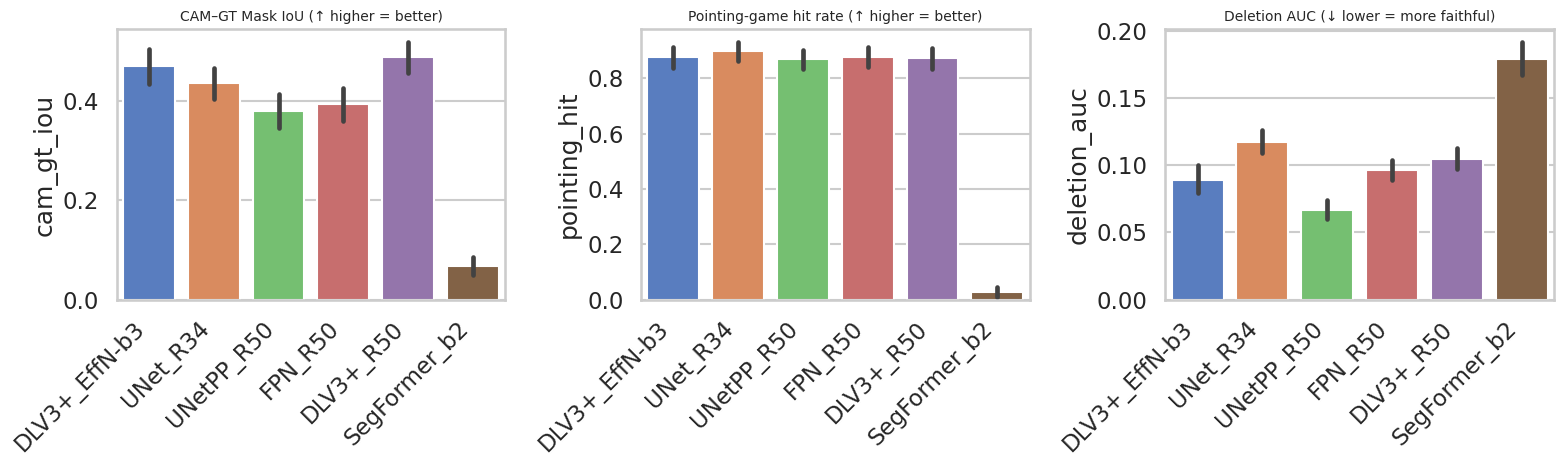

Saved xai_faithfulness_bars.png


In [11]:
MODEL_ORDER=["DeepLabV3Plus_efficientnet-b3","UNet_resnet34","UNetPP_resnet50",
             "FPN_resnet50","DeepLabV3Plus_resnet50","SegFormer_b2"]
MODEL_ORDER=[m for m in MODEL_ORDER if m in xai_per_image.model.unique()]

rows=[]
for name,grp in xai_per_image.groupby("model"):
    rows.append({"model":name,"n":len(grp),
                 "mean_cam_gt_iou":grp["cam_gt_iou"].mean(),
                 "mean_pointing_hit_rate":grp["pointing_hit"].mean(),
                 "mean_deletion_auc":grp["deletion_auc"].mean(),
                 "explanation_method":grp["explanation_method"].iloc[0]})
xai_summary=pd.DataFrame(rows).sort_values("mean_cam_gt_iou",ascending=False)
xai_summary.to_csv(OUTDIR/"xai_faithfulness_summary.csv",index=False)
print(xai_summary.to_string(index=False))

fig,axes=plt.subplots(1,3,figsize=(16,5))
short={m:m.replace("DeepLabV3Plus","DLV3+").replace("_resnet","_R").replace("_efficientnet","_EffN")
       for m in MODEL_ORDER}
for ax,(col,title,note) in zip(axes,[
    ("cam_gt_iou",        "CAM–GT Mask IoU",            "(↑ higher = better)"),
    ("pointing_hit",      "Pointing-game hit rate",     "(↑ higher = better)"),
    ("deletion_auc",      "Deletion AUC",               "(↓ lower = more faithful)"),
]):
    sub=xai_per_image.copy(); sub["model_short"]=sub["model"].map(short)
    order_s=[short[m] for m in MODEL_ORDER]
    sns.barplot(data=sub,x="model_short",y=col,order=order_s,ax=ax,
                hue="model_short",palette="muted",legend=False)
    ax.set_title(f"{title} {note}",fontsize=10); ax.set_xlabel("")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIG/"xai_faithfulness_bars.png",dpi=150,bbox_inches="tight"); plt.show()
print("Saved xai_faithfulness_bars.png")


**Step 7 — cross-link with Stages 2 & 3 + scatter plots (paper figure):**

Full cross-stage table:
                               fg_iou  severity_ccc  mean_cam_gt_iou  mean_pointing_hit_rate  mean_deletion_auc
model                                                                                                          
DeepLabV3Plus_resnet50         0.5904        0.7760           0.4889                  0.8733             0.1048
DeepLabV3Plus_efficientnet-b3  0.6304        0.8122           0.4712                  0.8767             0.0893
UNet_resnet34                  0.6129        0.8118           0.4359                  0.8967             0.1174
FPN_resnet50                   0.6135        0.7969           0.3934                  0.8767             0.0967
UNetPP_resnet50                0.5954        0.7983           0.3797                  0.8700             0.0666
SegFormer_b2                   0.5792        0.7610           0.0672                  0.0267             0.1789
corr(fg_IoU, mean_cam_gt_iou) = 0.641  |  corr(severity_ccc, mean_cam_gt_iou) = 

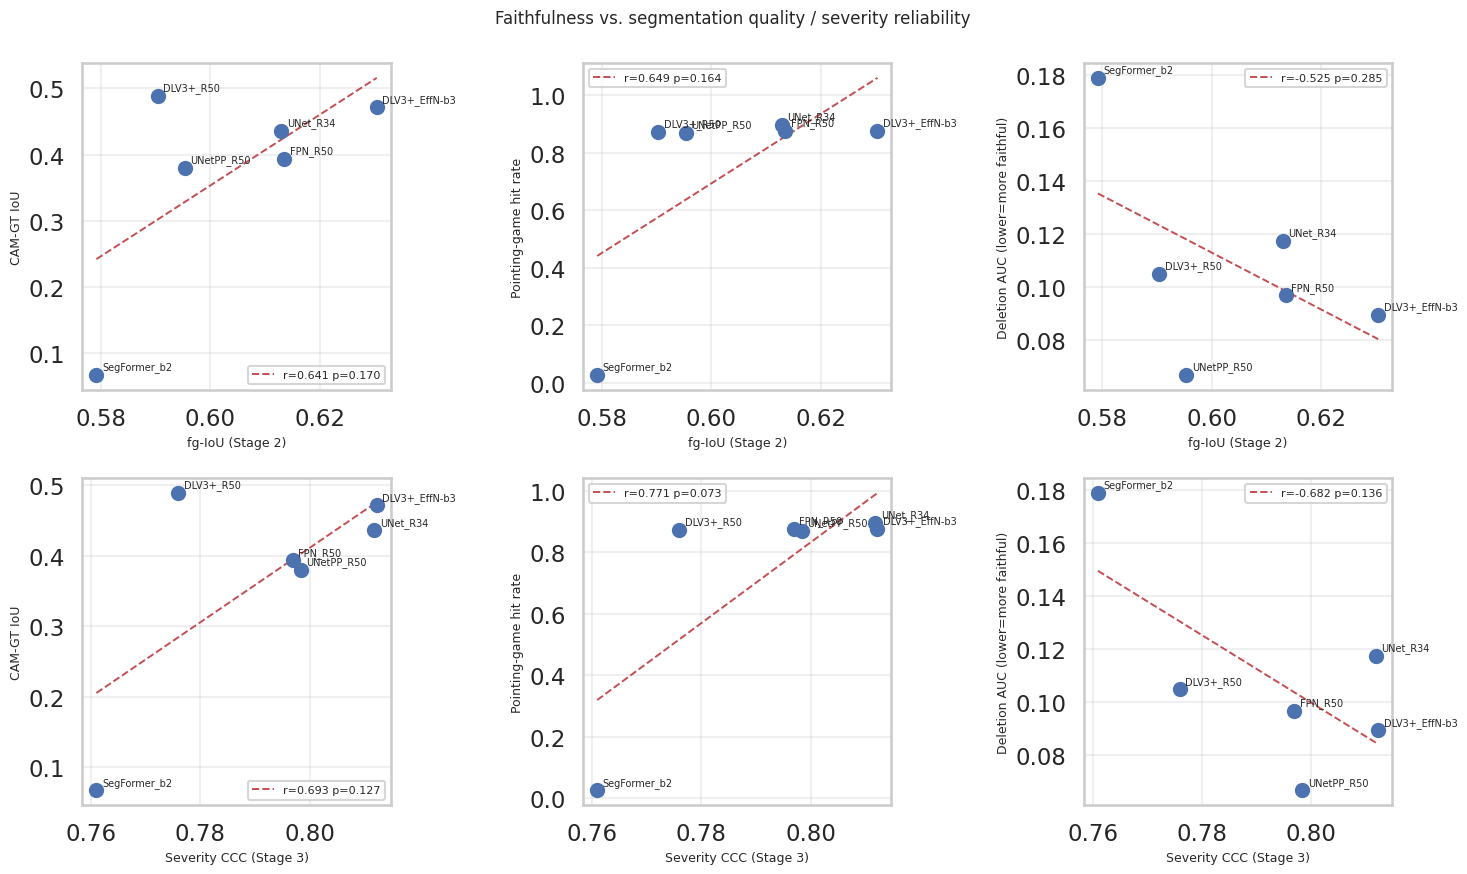

Saved xai_crosslink_scatter.png


In [12]:
# Cross-link: use Stage 3 reference loaded in config cell
final = xai_summary.set_index("model").join(stage3_ref, how="inner")
final.to_csv(OUTDIR/"xai_vs_segmentation_severity.csv")
print("Full cross-stage table:")
print(final[["fg_iou","severity_ccc","mean_cam_gt_iou","mean_pointing_hit_rate","mean_deletion_auc"]].round(4).to_string())

for ycol in ["mean_cam_gt_iou","mean_pointing_hit_rate","mean_deletion_auc"]:
    r1=final["fg_iou"].corr(final[ycol]); r2=final["severity_ccc"].corr(final[ycol])
    print(f"corr(fg_IoU, {ycol}) = {r1:.3f}  |  corr(severity_ccc, {ycol}) = {r2:.3f}")

# 2x3 scatter grid
fig,axes=plt.subplots(2,3,figsize=(15,9))
metrics=[("mean_cam_gt_iou","CAM-GT IoU"),
         ("mean_pointing_hit_rate","Pointing-game hit rate"),
         ("mean_deletion_auc","Deletion AUC (lower=more faithful)")]
xvars=[("fg_iou","fg-IoU (Stage 2)"),("severity_ccc","Severity CCC (Stage 3)")]
short={m:m.replace("DeepLabV3Plus","DLV3+").replace("_resnet","_R").replace("_efficientnet","_EffN")
       for m in final.index}
for row,(xcol,xlabel) in enumerate(xvars):
    for col,(ycol,ylabel) in enumerate(metrics):
        ax=axes[row,col]; xs=final[xcol].values; ys=final[ycol].values
        ax.scatter(xs,ys,s=90,zorder=3)
        for _,r in final.iterrows():
            ax.annotate(short[r.name],(r[xcol],r[ycol]),textcoords="offset points",xytext=(4,4),fontsize=7)
        m_,b_,r_,p_,_=stats.linregress(xs,ys)
        xr=np.linspace(xs.min(),xs.max(),50)
        ax.plot(xr,m_*xr+b_,"r--",lw=1.4,label=f"r={r_:.3f} p={p_:.3f}")
        ax.set_xlabel(xlabel,fontsize=9); ax.set_ylabel(ylabel,fontsize=9)
        ax.legend(fontsize=8); ax.grid(True,alpha=0.3)
plt.suptitle("Faithfulness vs. segmentation quality / severity reliability",fontsize=12)
plt.tight_layout()
plt.savefig(FIG/"xai_crosslink_scatter.png",dpi=150,bbox_inches="tight"); plt.show()
print("Saved xai_crosslink_scatter.png")


**Step 8 (REVISED 2026-09-19, Reviewer 2) \u2014 qualitative CAM / attention-rollout panel (paper Figure 23).** Best and worst faithfulness example per model, 6\u00d72 grid. Now includes a shared colour-map scale bar and an explicit per-row model-name label, per Reviewer 2's request.\n

In [ ]:
# == Step 8 (REVISED per Reviewer 2, Figure 23) ===============================
# R2: "annotate the scales of the colour maps used and the names of the models
# corresponding to the images." Adds: (1) a shared colour bar for the jet
# colormap's 0->1 attribution-intensity scale; (2) the model name (+ method)
# printed directly above each row (bold annotation, not just a rotated
# y-label, which is easy to miss/crop); (3) an explicit convention sentence
# in the suptitle. Requires the full Stage 4 context (models, explain(),
# eval_tf(), meta, IMG_SIZE, FIG, TRANSFORMER_MODELS, nc_by_model,
# xai_per_image) already loaded earlier in this notebook.

def cam_overlay(img_np, cam, alpha=0.5):
    heat = mpl_cm.jet(cam)[..., :3]
    return np.clip((1 - alpha) * img_np / 255. + alpha * heat, 0, 1)

valid = xai_per_image.dropna(subset=["cam_gt_iou"]).copy()
meta_ratio = meta.set_index("Name")["Mask ratio"]
valid["mask_ratio"] = valid["image"].map(meta_ratio)
thresh_ratio = valid["mask_ratio"].quantile(0.60)  # top 40% most-diseased
diseased = valid[valid["mask_ratio"] >= thresh_ratio]

examples = {}
for name, grp in diseased.groupby("model"):
    if len(grp) < 2:
        grp = valid[valid["model"] == name]
    examples[name] = {"high": grp.loc[grp["cam_gt_iou"].idxmax()],
                       "low":  grp.loc[grp["cam_gt_iou"].idxmin()]}

fig, axes = plt.subplots(len(MODEL_ORDER), 6, figsize=(18, 3.4 * len(MODEL_ORDER)),
                          gridspec_kw={"wspace": 0.04, "hspace": 0.55})
for j, ct in enumerate(["Image", "GT mask", "CAM (best IoU)", "Image", "GT mask", "CAM (worst IoU)"]):
    axes[0, j].set_title(ct, fontsize=9, fontweight="bold")

for i, name in enumerate(MODEL_ORDER):
    if name not in examples:
        continue
    is_tf = name in TRANSFORMER_MODELS; nc = nc_by_model[name]; model = models[name]
    for si, kind in enumerate(["high", "low"]):
        row_data = examples[name][kind]
        img_np = np.array(Image.open(row_data["filepath"]).convert("RGB"))
        gt_np  = np.array(Image.open(row_data["mask"]))
        a = eval_tf(image=img_np, mask=gt_np)
        x = a["image"].unsqueeze(0).to(device)
        cam = explain(model, x, nc, is_tf)
        img_rs = np.array(Image.fromarray(img_np).resize((IMG_SIZE, IMG_SIZE)))
        gt_rs  = (np.array(Image.fromarray(gt_np.astype(np.uint8) * 255).resize((IMG_SIZE, IMG_SIZE))) > 127)
        cb = si * 3
        axes[i, cb].imshow(img_rs); axes[i, cb].axis("off")
        axes[i, cb + 1].imshow(gt_rs, cmap="gray"); axes[i, cb + 1].axis("off")
        axes[i, cb + 2].imshow(cam_overlay(img_rs, cam), vmin=0, vmax=1)
        axes[i, cb + 2].axis("off")
        axes[i, cb + 2].set_title(f"IoU={row_data['cam_gt_iou']:.2f}", fontsize=7)

    short_n = name.replace("DeepLabV3Plus", "DLV3+").replace("_resnet", "_R").replace("_efficientnet", "_EffN")
    method = "Attention-rollout" if is_tf else "Grad-CAM"
    axes[i, 0].annotate(f"{short_n}  ({method})", xy=(0, 1.15), xycoords="axes fraction",
                          fontsize=9, fontweight="bold", ha="left", va="bottom")

cbar_ax = fig.add_axes([0.25, 0.005, 0.5, 0.012])
cbar = fig.colorbar(mpl_cm.ScalarMappable(cmap="jet", norm=plt.Normalize(0, 1)),
                     cax=cbar_ax, orientation="horizontal")
cbar.set_label("Attribution intensity (0 = low \u2192 1 = high; jet colormap: blue = low, red = high)", fontsize=9)

plt.suptitle(
    "Grad-CAM (CNN) / Attention-Rollout (SegFormer): best & worst examples per model\n"
    "Overlay colour encodes attribution intensity per the colour bar below "
    "(blue = low, red = high); IoU is CAM-vs-GT-mask overlap at the image's own ground-truth area threshold.",
    fontsize=11, y=1.02)
plt.savefig(FIG / "xai_cam_panel.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved xai_cam_panel.png with colour-map scale + per-row model names (Reviewer 2, Figure 23)")


**Step 9 (REVISED 2026-09-19, Reviewer 2) \u2014 pointing-game hit/miss EVENT COUNTS (paper Figure 21), replacing the box plots Reviewer 2 flagged as the wrong chart choice for a binary per-image outcome.**\n

In [ ]:
# == Step 9 (REVISED per Reviewer 2, Figure 21) ==============================
# R2: "The pointing-game hit distribution as a box plot is a wrong choice;
# simply show the counts of the resulting events." The pointing-game outcome
# is a per-image binary hit/miss (attribution peak inside vs. outside the
# ground-truth lesion mask), which a box plot obscures -- plot counts of that
# binary outcome per architecture instead. Saved under the SAME filename
# (xai_faithfulness_boxplots.png) so paper.tex needs no path change.

# Fall back to the saved CSV if this cell is run standalone (no GPU/model
# needed -- pointing_hit was already computed and exported in Step 5).
try:
    xai_per_image
except NameError:
    import pandas as pd
    for _cand in [OUTDIR/"xai_faithfulness_per_image.csv",
                  Path("/kaggle/working/s4_results/xai_faithfulness_per_image.csv"),
                  Path("xai_faithfulness_per_image.csv")]:
        if _cand.exists():
            xai_per_image = pd.read_csv(_cand); break
    else:
        raise FileNotFoundError("xai_faithfulness_per_image.csv not found -- run Step 5 first or point _cand at it.")

try:
    MODEL_ORDER
except NameError:
    MODEL_ORDER = ["DeepLabV3Plus_efficientnet-b3","UNet_resnet34","UNetPP_resnet50",
                   "FPN_resnet50","DeepLabV3Plus_resnet50","SegFormer_b2"]
    MODEL_ORDER = [m for m in MODEL_ORDER if m in xai_per_image.model.unique()]

short_map={m:m.replace("DeepLabV3Plus","DLV3+").replace("_resnet","_R").replace("_efficientnet","_EffN")
           for m in MODEL_ORDER}

counts = (
    xai_per_image.dropna(subset=["pointing_hit"])
    .assign(outcome=lambda d: d["pointing_hit"].map({True: "Hit", False: "Miss"}))
    .groupby(["model", "outcome"]).size().unstack(fill_value=0)
    .reindex(columns=["Hit", "Miss"], fill_value=0)
    .reindex(MODEL_ORDER)
)
counts["n"] = counts["Hit"] + counts["Miss"]
counts["hit_rate"] = counts["Hit"] / counts["n"]
counts.index = [short_map[m] for m in counts.index]

fig, ax = plt.subplots(figsize=(9, 5.5))
x = np.arange(len(counts))
width = 0.38
b_hit  = ax.bar(x - width/2, counts["Hit"],  width,
                 label="Hit \u2014 attribution peak inside GT lesion mask",  color="#2E7D32")
b_miss = ax.bar(x + width/2, counts["Miss"], width,
                 label="Miss \u2014 attribution peak outside GT lesion mask", color="#C62828")

for rects in (b_hit, b_miss):
    for rect in rects:
        h = rect.get_height()
        ax.annotate(f"{int(h)}", (rect.get_x() + rect.get_width()/2, h),
                     textcoords="offset points", xytext=(0, 3), ha="center", fontsize=8)

for xi in range(len(counts)):
    rate = counts["hit_rate"].iloc[xi]; n = counts["n"].iloc[xi]
    top = max(counts["Hit"].iloc[xi], counts["Miss"].iloc[xi])
    ax.annotate(f"{rate:.0%} hit rate (n={int(n)})", (xi, top + n * 0.06),
                 ha="center", fontsize=8, color="#333333")

ax.set_xticks(x); ax.set_xticklabels(counts.index, rotation=45, ha="right")
ax.set_ylabel("Number of images (n=300 stratified faithfulness subset)")
ax.set_title("Pointing-game outcome counts per architecture\n"
              "(Hit = attribution peak falls inside the ground-truth lesion mask)",
              fontsize=11)
ax.legend(fontsize=9, loc="upper right")
ax.grid(axis="y", alpha=0.3)
ax.set_ylim(0, counts["n"].max() * 1.2)
plt.tight_layout()
plt.savefig(FIG/"xai_faithfulness_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()
print(counts)
print("Saved xai_faithfulness_boxplots.png -- now a hit/miss COUNT bar chart (Reviewer 2, Figure 21)")


---
## End of Stage 4

All outputs saved to `/kaggle/working/s4_results/`:

**CSVs (for tables in the paper)**
- `xai_faithfulness_per_image.csv` — every XAI-subset image × all 6 models
- `xai_faithfulness_summary.csv` — per-model means of all 3 faithfulness metrics
- `xai_vs_segmentation_severity.csv` — full cross-stage table + correlations

**Figures (paper-ready, 150 dpi)**
- `figures/xai_faithfulness_bars.png` — bar charts of 3 faithfulness metrics by model
- `figures/xai_faithfulness_boxplots.png` — box plots (per-image distributions)
- `figures/xai_crosslink_scatter.png` — 2×3 scatter grid: faithfulness vs. fg-IoU & severity CCC
- `figures/xai_cam_panel.png` — qualitative Grad-CAM / attention-rollout panel (best & worst per model)


**Save & verify all Stage 4 outputs — creates `plantseg_stage4_results.zip` in the Output tab:**

In [15]:
# ── Save & verify all Stage 4 outputs ──────────────────────────────────────
import zipfile
from pathlib import Path

OUT  = Path("/kaggle/working/s4_results")
FIG2 = OUT / "figures"

expected = {
    # CSVs
    OUT/"xai_faithfulness_per_image.csv":     "Per-image XAI results (1800 rows)",
    OUT/"xai_faithfulness_summary.csv":       "Per-model faithfulness summary",
    OUT/"xai_vs_segmentation_severity.csv":   "Cross-stage table (Stages 2-3-4)",
    # Figures
    FIG2/"xai_faithfulness_bars.png":         "Bar chart — 3 faithfulness metrics",
    FIG2/"xai_faithfulness_boxplots.png":     "Box plots — per-image distributions",
    FIG2/"xai_crosslink_scatter.png":         "2x3 cross-link scatter grid",
    FIG2/"xai_cam_panel.png":                 "Qualitative CAM / attention panel",
}

print(f"{'File':<52} {'Size':>9}  Status")
print("-" * 70)
missing = []
for p, desc in expected.items():
    if p.exists():
        size = f"{p.stat().st_size/1024:.1f} KB"
        print(f"{p.name:<52} {size:>9}  OK")
    else:
        print(f"{p.name:<52} {'':>9}  MISSING")
        missing.append(p)

print(f"\n{len(expected)-len(missing)}/{len(expected)} files present.")
if missing:
    print("MISSING:", [p.name for p in missing])

# Zip everything into one archive
zip_path = Path("/kaggle/working/plantseg_stage4_results.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in expected:
        if p.exists():
            # preserve sub-folder structure: figures/xxx.png vs xxx.csv
            arcname = p.relative_to(OUT)
            zf.write(p, arcname)

print(f"\nArchive: {zip_path.name}  ({zip_path.stat().st_size/1024/1024:.2f} MB)")
print("Download from Kaggle Output tab → plantseg_stage4_results.zip")


File                                                      Size  Status
----------------------------------------------------------------------
xai_faithfulness_per_image.csv                        506.7 KB  OK
xai_faithfulness_summary.csv                            0.6 KB  OK
xai_vs_segmentation_severity.csv                        0.8 KB  OK
xai_faithfulness_bars.png                             120.7 KB  OK
xai_faithfulness_boxplots.png                         146.8 KB  OK
xai_crosslink_scatter.png                             257.0 KB  OK
xai_cam_panel.png                                    4106.9 KB  OK

7/7 files present.

Archive: plantseg_stage4_results.zip  (4.51 MB)
Download from Kaggle Output tab → plantseg_stage4_results.zip
